In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/valorantphoenix/refit-hh/RAW_House1_Part1.csv
/kaggle/input/datasets/valorantphoenix/refit-hh/RAW_House1_Part2.csv


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

%matplotlib inline

In [3]:
df1= pd.read_csv('/kaggle/input/datasets/valorantphoenix/refit-hh/RAW_House1_Part1.csv')
df2= pd.read_csv('/kaggle/input/datasets/valorantphoenix/refit-hh/RAW_House1_Part2.csv')

In [4]:
df1.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [5]:
df2.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2014-06-27 21:57:50,1403906269,322.0,0.0,0.0,72.0,0.0,0.0,0.0,0.0,NaN,NaN
1,2014-06-27 21:57:51,1403906271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,1.0
2,2014-06-27 21:57:58,1403906278,329.0,NaN,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN
3,2014-06-27 21:58:06,1403906286,322.0,0.0,0.0,71.0,NaN,NaN,NaN,0.0,30.0,NaN
4,2014-06-27 21:58:14,1403906293,320.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN


In [6]:
MAX_FILL_MIN = 5          # gaps up to 5 min are interpolated; longer = flagged
MAX_POWER_W = 15000       # aggregate above this is impossible (~65 A x 230 V)
MAX_APPLIANCE_W = 4000    # appliance spike limit (same as official REFIT cleaning)
MIN_POWER_W = 0           # negative power is impossible
FREQ = "1min"
# House 1 (README): Appliance1 = Fridge, Appliance5 = Washing Machine
PLOT_APPLIANCES = ["Appliance1", "Appliance5"]
WASHER_COL = "Appliance5"

def max_limit(col):
    return MAX_POWER_W if col == "Aggregate" else MAX_APPLIANCE_W

In [7]:
def load_raw(paths):
    """Load raw CSV parts and concatenate. Rows are sparse (each row may hold only
    some channels, others NaN): staggered logging, handled by the 1-min mean resample."""
    if isinstance(paths, str):
        paths = [paths]
    parts = []
    for p in paths:
        part = pd.read_csv(p)
        part.columns = [c.strip() for c in part.columns]
        part["source_file"] = Path(p).name
        parts.append(part)
    df = pd.concat(parts, ignore_index=True)
    # Unix column is seconds since epoch (UTC)
    df["timestamp"] = pd.to_datetime(pd.to_numeric(df["Unix"], errors="coerce"), unit="s", utc=True)
    return df

In [8]:
def inspect(df, power_cols):
    f = {}
    f["n_rows"] = int(len(df))
    f["n_unparseable_timestamps"] = int(df["timestamp"].isna().sum())
    ts = df["timestamp"].dropna()
    f["start"], f["end"] = str(ts.min()), str(ts.max())
    f["is_sorted_monotonic_increasing"] = bool(ts.is_monotonic_increasing)
    f["n_out_of_order_steps"] = int((ts.diff().dt.total_seconds() < 0).sum())
    f["n_duplicate_timestamps"] = int(ts.duplicated().sum())

    ts_sorted = ts.drop_duplicates().sort_values()
    gap_s = ts_sorted.diff().dt.total_seconds()
    dt = gap_s.dropna()
    f["sampling_interval_sec"] = {
        "median": float(dt.median()), "mean": float(dt.mean()),
        "p01": float(dt.quantile(0.01)), "p99": float(dt.quantile(0.99)),
        "max": float(dt.max()),
    }
    f["share_intervals_between_6_and_10_sec"] = float(((dt >= 6) & (dt <= 10)).mean())
    f["n_gaps_gt_1min"] = int((dt > 60).sum())
    f["n_gaps_gt_1hour"] = int((dt > 3600).sum())
    f["n_gaps_gt_1day"] = int((dt > 86400).sum())
    prev = ts_sorted.shift(1)
    f["largest_gaps"] = [
        {"gap_start": str(prev.loc[i]), "gap_end": str(ts_sorted.loc[i]), "gap_hours": round(v / 3600, 2)}
        for i, v in gap_s.nlargest(5).items()
    ]
    f["missing_values"] = {c: int(df[c].isna().sum()) for c in power_cols}
    f["negative_values"] = {c: int((df[c] < MIN_POWER_W).sum()) for c in power_cols}
    f["above_max_power"] = {c: int((df[c] > max_limit(c)).sum()) for c in power_cols}
    f["describe"] = df[power_cols].describe(percentiles=[0.5, 0.99, 0.999]).round(2).to_dict()
    return f

In [9]:
def clean(df, power_cols):
    stats = {}
    d = df.dropna(subset=["timestamp"]).copy()

    # 1) sort
    d = d.sort_values("timestamp")

    # 2) duplicates: average readings sharing the same timestamp
    stats["duplicate_rows_collapsed"] = int(d["timestamp"].duplicated().sum())
    d = d.groupby("timestamp", as_index=True)[power_cols].mean()

    # 3) impossible values -> NaN (not clipped)
    upper = pd.Series({c: max_limit(c) for c in power_cols})
    bad = (d[power_cols] < MIN_POWER_W) | (d[power_cols] > upper)
    stats["impossible_values_set_nan"] = {c: int(bad[c].sum()) for c in power_cols}
    d = d.mask(bad)

    # 4) resample to 1-min mean onto a full regular grid
    r = d.resample(FREQ).mean()
    r = r.reindex(pd.date_range(r.index.min(), r.index.max(), freq=FREQ, tz=r.index.tz))
    stats["n_minutes_total"] = int(len(r))
    stats["n_minutes_missing_before_fill"] = {c: int(r[c].isna().sum()) for c in power_cols}

    # 5) fill short gaps, flag long gaps
    clean_df = pd.DataFrame(index=r.index)
    for c in power_cols:
        s = r[c]
        is_nan = s.isna()
        run_id = (is_nan != is_nan.shift()).cumsum()
        run_len = is_nan.groupby(run_id).transform("sum")
        long_gap = is_nan & (run_len > MAX_FILL_MIN)
        filled = s.interpolate(method="time", limit=MAX_FILL_MIN, limit_area="inside")
        filled = filled.mask(long_gap)   # undo partial fill inside long gaps
        clean_df[c] = filled
        clean_df[f"{c}_long_gap"] = long_gap
        clean_df[f"{c}_filled"] = is_nan & ~long_gap & filled.notna()

    clean_df["long_gap"] = clean_df["Aggregate_long_gap"]
    stats["n_minutes_filled_short_gaps"] = {c: int(clean_df[f"{c}_filled"].sum()) for c in power_cols}
    stats["n_minutes_flagged_long_gap"] = {c: int(clean_df[f"{c}_long_gap"].sum()) for c in power_cols}

    g = clean_df["long_gap"]
    run = (g != g.shift()).cumsum()
    outs = []
    for _, seg in g.groupby(run):
        if seg.iloc[0]:
            outs.append({"start": str(seg.index[0]), "end": str(seg.index[-1]), "minutes": int(len(seg))})
    stats["n_long_outages_aggregate"] = len(outs)
    stats["longest_outages_aggregate"] = sorted(outs, key=lambda x: -x["minutes"])[:10]
    return clean_df, stats

In [10]:
def make_plots(raw, clean_df, power_cols, out):
    # pick a well-covered day where the washer ran, so the plot is not flat
    daily_cov = clean_df["Aggregate"].notna().resample("D").mean()
    good_days = daily_cov[daily_cov > 0.95].index
    if len(good_days):
        washer_daily = clean_df[WASHER_COL].resample("D").sum().reindex(good_days)
        start = washer_daily.idxmax()
    else:
        start = clean_df.index[0]
    end = start + pd.Timedelta(days=2)

    raw_idx = raw.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    raw_w = raw_idx.loc[start:end]
    cl_w = clean_df.loc[start:end]

    chans = ["Aggregate"] + PLOT_APPLIANCES
    fig, axes = plt.subplots(len(chans), 2, figsize=(15, 8), sharex="col")
    for i, c in enumerate(chans):
        axes[i, 0].plot(raw_w.index, raw_w[c], lw=0.5, color="tab:red")
        axes[i, 0].set_ylabel(f"{c} (W)")
        axes[i, 1].plot(cl_w.index, cl_w[c], lw=0.7, color="tab:blue")
        flagged = cl_w[f"{c}_filled"]
        if flagged.any():
            axes[i, 1].scatter(cl_w.index[flagged], cl_w[c][flagged], s=6, color="orange",
                               label="interpolated", zorder=3)
            axes[i, 1].legend(loc="upper right")
    axes[0, 0].set_title("BEFORE: raw (~8 s)")
    axes[0, 1].set_title(f"AFTER: cleaned 1-min (gaps > {MAX_FILL_MIN} min left blank)")
    fig.suptitle(f"House 1, {start.date()} to {end.date()}")
    fig.tight_layout()
    fig.savefig(out / "before_after_2day.png", dpi=130)
    plt.show()

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(clean_df.index, clean_df["Aggregate"], lw=0.3)
    ax.fill_between(clean_df.index, 0, 1, where=clean_df["long_gap"].values,
                    transform=ax.get_xaxis_transform(), color="red", alpha=0.3,
                    label="long gap (flagged, not filled)")
    ax.set_ylabel("Aggregate (W)")
    ax.set_title("House 1 cleaned aggregate, full range")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "full_range_aggregate.png", dpi=130)
    plt.show()

    ts = raw_idx.index.drop_duplicates()
    dt = pd.Series(ts).diff().dt.total_seconds().dropna()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(dt[dt <= 30], bins=60)
    ax.set_xlabel("Interval between readings (s), clipped at 30 s")
    ax.set_ylabel("Count")
    ax.set_title("Raw sampling-interval distribution")
    fig.tight_layout()
    fig.savefig(out / "raw_interval_hist.png", dpi=130)
    plt.show()

In [11]:
RAW_PATHS = [
    "/kaggle/input/datasets/valorantphoenix/refit-hh/RAW_House1_Part1.csv",
    "/kaggle/input/datasets/valorantphoenix/refit-hh/RAW_House1_Part2.csv",
]
OUT = Path("/kaggle/working/outputs/section1")
OUT.mkdir(parents=True, exist_ok=True)

df = load_raw(RAW_PATHS)
power_cols = [c for c in df.columns if c == "Aggregate" or c.lower().startswith("appliance")]
print(power_cols)
df.head()

['Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,source_file,timestamp
0,2013-10-09 14:06:17,1381327577,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0,RAW_House1_Part1.csv,2013-10-09 14:06:17+00:00
1,2013-10-09 14:06:31,1381327591,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0,RAW_House1_Part1.csv,2013-10-09 14:06:31+00:00
2,2013-10-09 14:06:46,1381327606,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0,RAW_House1_Part1.csv,2013-10-09 14:06:46+00:00
3,2013-10-09 14:07:01,1381327621,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0,RAW_House1_Part1.csv,2013-10-09 14:07:01+00:00
4,2013-10-09 14:07:15,1381327634,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0,RAW_House1_Part1.csv,2013-10-09 14:07:14+00:00


In [12]:
findings = inspect(df, power_cols)
print(json.dumps({k: v for k, v in findings.items() if k != "describe"}, indent=2, default=str))

{
  "n_rows": 8518763,
  "n_unparseable_timestamps": 0,
  "start": "2013-10-09 14:06:17+00:00",
  "end": "2015-07-10 11:56:32+00:00",
  "is_sorted_monotonic_increasing": false,
  "n_out_of_order_steps": 2,
  "n_duplicate_timestamps": 1211048,
  "sampling_interval_sec": {
    "median": 7.0,
    "mean": 7.553910155761432,
    "p01": 1.0,
    "p99": 15.0,
    "max": 3594414.0
  },
  "share_intervals_between_6_and_10_sec": 0.5315941483205281,
  "n_gaps_gt_1min": 4040,
  "n_gaps_gt_1hour": 21,
  "n_gaps_gt_1day": 12,
  "largest_gaps": [
    {
      "gap_start": "2014-01-24 01:56:25+00:00",
      "gap_end": "2014-03-06 16:23:19+00:00",
      "gap_hours": 998.45
    },
    {
      "gap_start": "2015-05-10 23:36:10+00:00",
      "gap_end": "2015-05-19 15:10:21+00:00",
      "gap_hours": 207.57
    },
    {
      "gap_start": "2015-06-10 13:19:01+00:00",
      "gap_end": "2015-06-18 01:39:44+00:00",
      "gap_hours": 180.35
    },
    {
      "gap_start": "2015-04-03 01:43:17+00:00",
      "ga

In [13]:
clean_df, stats = clean(df, power_cols)
findings["cleaning"] = stats
findings["config"] = {"MAX_FILL_MIN": MAX_FILL_MIN, "MAX_POWER_W": MAX_POWER_W,
                      "MAX_APPLIANCE_W": MAX_APPLIANCE_W, "MIN_POWER_W": MIN_POWER_W, "FREQ": FREQ}
print(json.dumps(stats, indent=2, default=str))
clean_df.head()

{
  "duplicate_rows_collapsed": 1211048,
  "impossible_values_set_nan": {
    "Aggregate": 151,
    "Appliance1": 787,
    "Appliance2": 35,
    "Appliance3": 116,
    "Appliance4": 1543,
    "Appliance5": 192,
    "Appliance6": 33,
    "Appliance7": 373,
    "Appliance8": 151,
    "Appliance9": 43
  },
  "n_minutes_total": 920031,
  "n_minutes_missing_before_fill": {
    "Aggregate": 115142,
    "Appliance1": 117694,
    "Appliance2": 118516,
    "Appliance3": 116588,
    "Appliance4": 116148,
    "Appliance5": 123556,
    "Appliance6": 115968,
    "Appliance7": 115148,
    "Appliance8": 116782,
    "Appliance9": 212965
  },
  "n_minutes_filled_short_gaps": {
    "Aggregate": 864,
    "Appliance1": 2144,
    "Appliance2": 2129,
    "Appliance3": 892,
    "Appliance4": 967,
    "Appliance5": 3114,
    "Appliance6": 768,
    "Appliance7": 859,
    "Appliance8": 1584,
    "Appliance9": 1304
  },
  "n_minutes_flagged_long_gap": {
    "Aggregate": 114278,
    "Appliance1": 115550,
    "App

,Aggregate,Aggregate_long_gap,Aggregate_filled,Appliance1,Appliance1_long_gap,Appliance1_filled,Appliance2,Appliance2_long_gap,Appliance2_filled,Appliance3,...,Appliance7,Appliance7_long_gap,Appliance7_filled,Appliance8,Appliance8_long_gap,Appliance8_filled,Appliance9,Appliance9_long_gap,Appliance9_filled,long_gap
2013-10-09 14:06:00+00:00,529.666667,False,False,74.333333,False,False,0.0,False,False,68.666667,...,0.0,False,False,0.0,False,False,1.0,False,False,False
2013-10-09 14:07:00+00:00,543.875000,False,False,73.875000,False,False,0.0,False,False,68.750000,...,0.0,False,False,0.0,False,False,1.0,False,False,False
2013-10-09 14:08:00+00:00,572.444444,False,False,73.111111,False,False,0.0,False,False,46.555556,...,0.0,False,False,0.0,False,False,1.0,False,False,False
2013-10-09 14:09:00+00:00,638.300000,False,False,72.800000,False,False,0.0,False,False,0.000000,...,0.0,False,False,0.0,False,False,1.0,False,False,False
2013-10-09 14:10:00+00:00,800.200000,False,False,72.000000,False,False,0.0,False,False,0.000000,...,0.0,False,False,0.0,False,False,1.0,False,False,False


In [14]:
STUCK_MIN = 60     # minutes of identical value
STUCK_MIN_W = 100  # only flag if value is above this (off/standby flat lines are legit)

def flag_stuck(s, min_len=STUCK_MIN, min_w=STUCK_MIN_W):
    x = s.round(0)
    new_run = x.ne(x.shift()) | x.isna()
    run_id = new_run.cumsum()
    run_len = x.groupby(run_id).transform("size")
    return (run_len >= min_len) & (x > min_w) & x.notna()

stats["stuck_minutes"] = {}
for c in power_cols:
    st = flag_stuck(clean_df[c])
    clean_df[f"{c}_stuck"] = st
    clean_df[c] = clean_df[c].mask(st)
    stats["stuck_minutes"][c] = int(st.sum())
findings["cleaning"] = stats
print(stats["stuck_minutes"])

{'Aggregate': 3421, 'Appliance1': 0, 'Appliance2': 0, 'Appliance3': 0, 'Appliance4': 240, 'Appliance5': 168, 'Appliance6': 0, 'Appliance7': 0, 'Appliance8': 0, 'Appliance9': 4309}


In [15]:
d = df.dropna(subset=["timestamp"])
print(d.groupby("source_file")["timestamp"].agg(["min", "max", "count"]))
dup = d[d["timestamp"].duplicated(keep=False)]
print(dup.groupby("timestamp")["source_file"].nunique().value_counts())

                                           min                       max  \
source_file                                                                
RAW_House1_Part1.csv 2013-10-09 14:06:17+00:00 2014-10-01 01:27:07+00:00   
RAW_House1_Part2.csv 2014-06-27 21:57:49+00:00 2015-07-10 11:56:32+00:00   

                        count  
source_file                    
RAW_House1_Part1.csv  4377877  
RAW_House1_Part2.csv  4140886  
source_file
1    764126
2    191889
Name: count, dtype: int64


In [16]:
is_p1 = df["source_file"].str.contains("Part1")
p2_start = df.loc[df["source_file"].str.contains("Part2"), "timestamp"].min()
overlap = is_p1 & (df["timestamp"] >= p2_start)
print("Part1 overlap rows dropped:", int(overlap.sum()))
df = df[~overlap]

Part1 overlap rows dropped: 1257865


In [17]:
st = clean_df["Aggregate_stuck"]
run = (st != st.shift()).cumsum()
runs = [(seg.index[0], seg.index[-1], len(seg)) for _, seg in st.groupby(run) if seg.iloc[0]]
print(len(runs), "stuck runs")
for r in sorted(runs, key=lambda x: -x[2])[:10]:
    print(r)

12 stuck runs
(Timestamp('2014-08-01 17:13:00+0000', tz='UTC'), Timestamp('2014-08-02 13:58:00+0000', tz='UTC'), 1246)
(Timestamp('2014-09-06 22:52:00+0000', tz='UTC'), Timestamp('2014-09-07 13:23:00+0000', tz='UTC'), 872)
(Timestamp('2015-02-18 16:18:00+0000', tz='UTC'), Timestamp('2015-02-18 21:40:00+0000', tz='UTC'), 323)
(Timestamp('2014-09-07 14:42:00+0000', tz='UTC'), Timestamp('2014-09-07 18:34:00+0000', tz='UTC'), 233)
(Timestamp('2015-02-08 13:24:00+0000', tz='UTC'), Timestamp('2015-02-08 16:11:00+0000', tz='UTC'), 168)
(Timestamp('2014-07-21 11:11:00+0000', tz='UTC'), Timestamp('2014-07-21 13:07:00+0000', tz='UTC'), 117)
(Timestamp('2014-10-04 15:28:00+0000', tz='UTC'), Timestamp('2014-10-04 17:05:00+0000', tz='UTC'), 98)
(Timestamp('2015-02-14 15:55:00+0000', tz='UTC'), Timestamp('2015-02-14 17:22:00+0000', tz='UTC'), 88)
(Timestamp('2014-07-14 00:42:00+0000', tz='UTC'), Timestamp('2014-07-14 01:52:00+0000', tz='UTC'), 71)
(Timestamp('2014-11-01 14:04:00+0000', tz='UTC'), Ti

In [18]:
# 1) Overlap drop (agar pehle chal chuka hai toh 0 rows dropped dikhayega, koi dikkat nahi)
is_p1 = df["source_file"].str.contains("Part1")
p2_start = df.loc[df["source_file"].str.contains("Part2"), "timestamp"].min()
overlap = is_p1 & (df["timestamp"] >= p2_start)
print("Part1 overlap rows dropped:", int(overlap.sum()))
df = df[~overlap]

# 2) Clean
clean_df, stats = clean(df, power_cols)

# 3) Stuck-value rule
STUCK_MIN = 60
STUCK_MIN_W = 100

def flag_stuck(s, min_len=STUCK_MIN, min_w=STUCK_MIN_W):
    x = s.round(0)
    new_run = x.ne(x.shift()) | x.isna()
    run_id = new_run.cumsum()
    run_len = x.groupby(run_id).transform("size")
    return (run_len >= min_len) & (x > min_w) & x.notna()

stats["stuck_minutes"] = {}
for c in power_cols:
    st = flag_stuck(clean_df[c])
    clean_df[f"{c}_stuck"] = st
    clean_df[c] = clean_df[c].mask(st)
    stats["stuck_minutes"][c] = int(st.sum())

findings["cleaning"] = stats
findings["config"] = {"MAX_FILL_MIN": MAX_FILL_MIN, "MAX_POWER_W": MAX_POWER_W,
                      "MAX_APPLIANCE_W": MAX_APPLIANCE_W, "MIN_POWER_W": MIN_POWER_W,
                      "FREQ": FREQ, "STUCK_MIN": STUCK_MIN, "STUCK_MIN_W": STUCK_MIN_W}
print(json.dumps(stats, indent=2, default=str))

Part1 overlap rows dropped: 0
{
  "duplicate_rows_collapsed": 597182,
  "impossible_values_set_nan": {
    "Aggregate": 147,
    "Appliance1": 762,
    "Appliance2": 35,
    "Appliance3": 116,
    "Appliance4": 1010,
    "Appliance5": 70,
    "Appliance6": 33,
    "Appliance7": 373,
    "Appliance8": 149,
    "Appliance9": 43
  },
  "n_minutes_total": 920031,
  "n_minutes_missing_before_fill": {
    "Aggregate": 119692,
    "Appliance1": 123778,
    "Appliance2": 123473,
    "Appliance3": 121143,
    "Appliance4": 132837,
    "Appliance5": 129691,
    "Appliance6": 120560,
    "Appliance7": 119701,
    "Appliance8": 121889,
    "Appliance9": 338427
  },
  "n_minutes_filled_short_gaps": {
    "Aggregate": 899,
    "Appliance1": 2801,
    "Appliance2": 2371,
    "Appliance3": 930,
    "Appliance4": 3232,
    "Appliance5": 3567,
    "Appliance6": 839,
    "Appliance7": 894,
    "Appliance8": 1859,
    "Appliance9": 1061
  },
  "n_minutes_flagged_long_gap": {
    "Aggregate": 118793,
    "

In [19]:
valid_agg = clean_df["Aggregate"].notna()   # excludes long gaps AND stuck minutes
valid_wm = valid_agg & clean_df["Appliance5"].notna()
print(valid_agg.mean().round(3), valid_wm.mean().round(3))

0.867 0.859


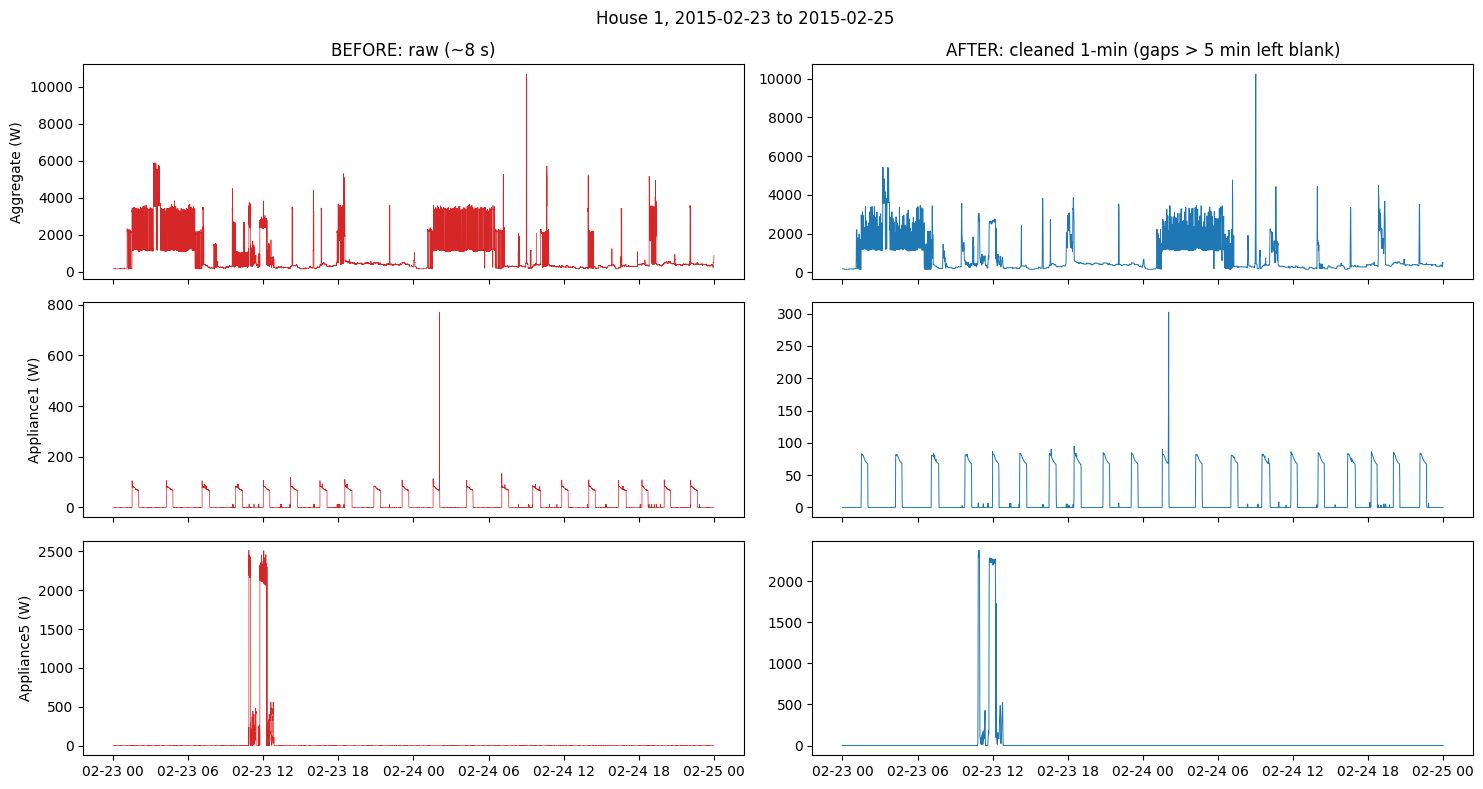

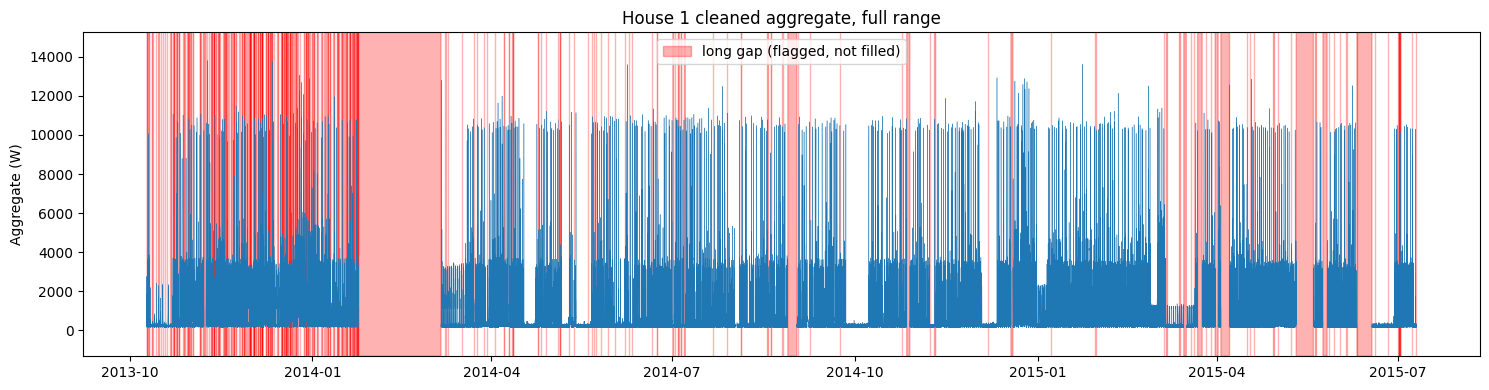

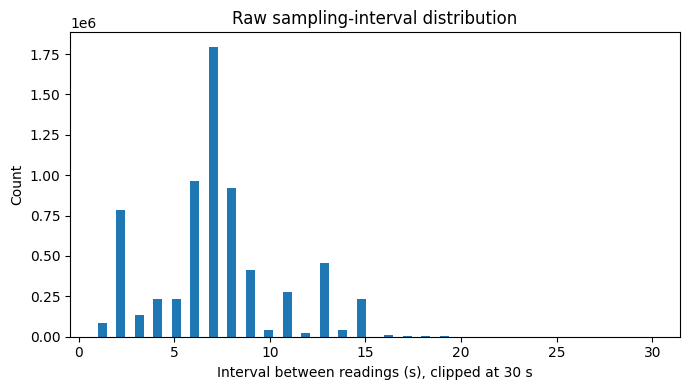

In [20]:
make_plots(df, clean_df, power_cols, OUT)

In [21]:
clean_df.to_csv(OUT / "house1_clean_1min.csv.gz", compression="gzip")
with open(OUT / "section1_findings.json", "w") as fh:
    json.dump(findings, fh, indent=2, default=str)
print("Saved in", OUT)

Saved in /kaggle/working/outputs/section1
